<a href="https://colab.research.google.com/github/ShachiPradhan/CODSOFT_TASKNO_3/blob/main/IRIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving IRIS.csv to IRIS.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set consistent style
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

df = pd.read_csv('IRIS.csv')

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nSpecies counts:\n", df['species'].value_counts())
print("\nStatistics:\n", df.describe())

# Clean index right away — lesson learned from last time
df = df.reset_index(drop=True)
print("\nIndex unique:", df.index.is_unique)   # should be True

Shape: (150, 5)

Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Data types:
 sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
 species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Statistics:
        sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000

In [3]:
df['species'] = df['species'].str.replace('Iris-', '', regex=False)
print(df['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


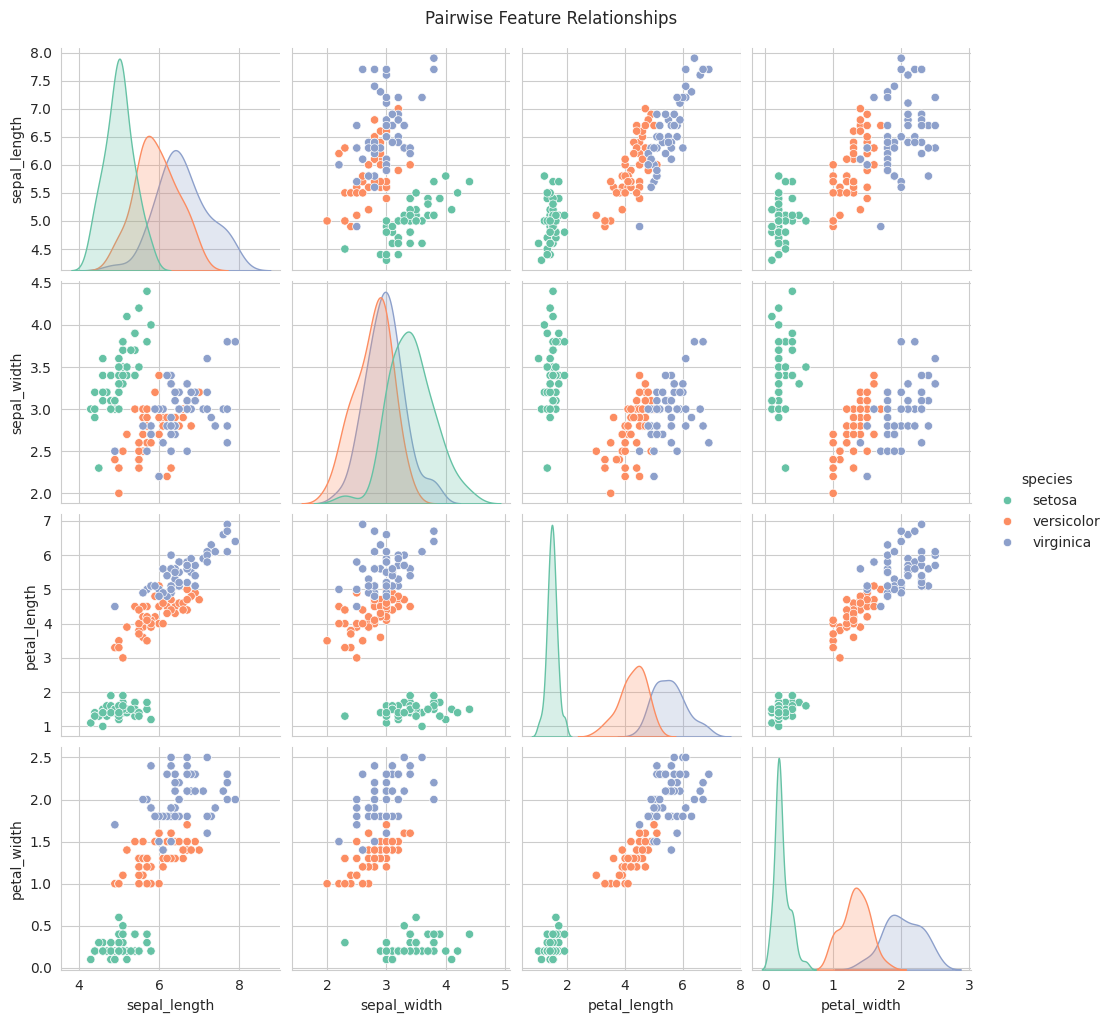

In [4]:
sns.pairplot(df, hue='species', palette='Set2', diag_kind='kde')
plt.suptitle('Pairwise Feature Relationships', y=1.02)
plt.show()

/tmp/ipykernel_1060/2885657790.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feat, ax=ax, palette='Set2')
/tmp/ipykernel_1060/2885657790.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feat, ax=ax, palette='Set2')
/tmp/ipykernel_1060/2885657790.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feat, ax=ax, palette='Set2')
/tmp/ipykernel_1060/2885657790.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.

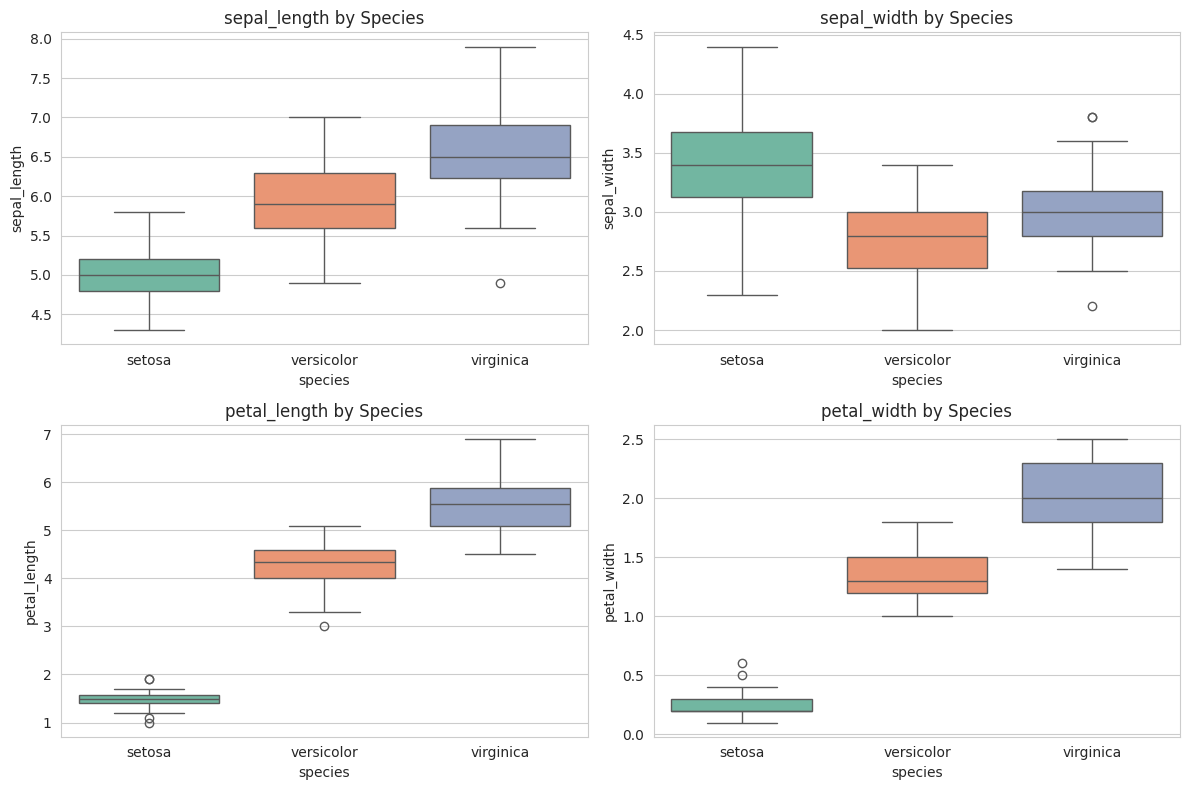

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

for ax, feat in zip(axes.flatten(), features):
    sns.boxplot(data=df, x='species', y=feat, ax=ax, palette='Set2')
    ax.set_title(f'{feat} by Species')

plt.tight_layout()
plt.show()

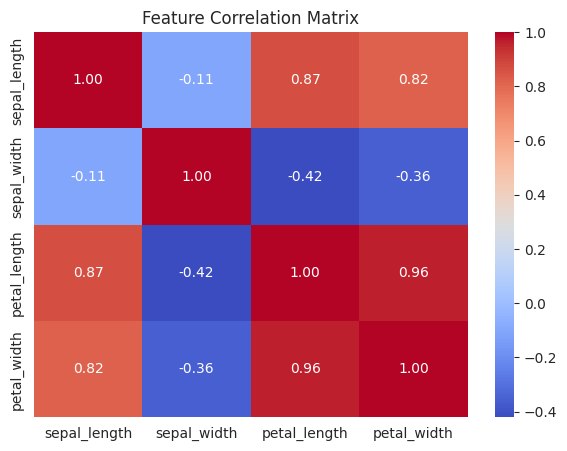

In [7]:

plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns='species').corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

In [8]:
X = df.drop(columns='species')
y = df['species']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (150, 4)
Target: (150,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y              # ← keeps class balance in both splits
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))

Train: (120, 4) | Test: (30, 4)

Train class balance:
 species
setosa        0.333333
virginica     0.333333
versicolor    0.333333
Name: proportion, dtype: float64

Test class balance:
 species
setosa        0.333333
virginica     0.333333
versicolor    0.333333
Name: proportion, dtype: float64


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'KNN (k=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
    'Decision Tree': Pipeline([
        ('clf', DecisionTreeClassifier(random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('clf', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
    ]),
    'Gradient Boosting': Pipeline([
        ('clf', GradientBoostingClassifier(random_state=42))
    ]),
    'Naive Bayes': Pipeline([
        ('clf', GaussianNB())
    ]),
}

In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score

results = []

for name, model in models.items():
    # Cross-validation (5-fold, stratified by default)
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

    # Fit on full train set and evaluate on test
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std(),
        'Test Acc': accuracy_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values('Test Acc', ascending=False)
print(results_df.to_string(index=False))

              Model  CV Mean   CV Std  Test Acc
          SVM (RBF) 0.966667 0.031180  0.966667
  Gradient Boosting 0.966667 0.016667  0.966667
        Naive Bayes 0.958333 0.026352  0.966667
          KNN (k=5) 0.966667 0.031180  0.933333
Logistic Regression 0.958333 0.026352  0.933333
      Decision Tree 0.941667 0.020412  0.933333
      Random Forest 0.950000 0.016667  0.900000


In [13]:
from sklearn.model_selection import GridSearchCV

# Tune SVM
svm_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(probability=True, random_state=42))
])

svm_params = {
    'clf__C': [0.1, 1, 10, 100],
    'clf__gamma': ['scale', 0.01, 0.1, 1],
    'clf__kernel': ['rbf', 'linear']
}

svm_grid = GridSearchCV(svm_pipe, svm_params, cv=5,
                        scoring='accuracy', n_jobs=-1, verbose=1)
svm_grid.fit(X_train, y_train)

print("Best SVM params:", svm_grid.best_params_)
print("Best CV score:", svm_grid.best_score_)
print("Test accuracy:", svm_grid.score(X_test, y_test))

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best SVM params: {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
Best CV score: 0.975
Test accuracy: 0.9333333333333333


In [14]:
rf_pipe = Pipeline([
    ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

rf_params = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [None, 3, 5, 7],
    'clf__min_samples_split': [2, 3, 5]
}

rf_grid = GridSearchCV(rf_pipe, rf_params, cv=5,
                       scoring='accuracy', n_jobs=-1, verbose=1)
rf_grid.fit(X_train, y_train)

print("Best RF params:", rf_grid.best_params_)
print("Best CV score:", rf_grid.best_score_)
print("Test accuracy:", rf_grid.score(X_test, y_test))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best RF params: {'clf__max_depth': 3, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}
Best CV score: 0.9583333333333334
Test accuracy: 0.9666666666666667


In [15]:
# pip install xgboost
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# XGBoost needs numeric labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42
)

xgb.fit(X_train, y_train_enc)
xgb_pred = xgb.predict(X_test)
print("XGBoost Test Accuracy:", accuracy_score(y_test_enc, xgb_pred))
print("\nClassification Report:\n",
      classification_report(y_test_enc, xgb_pred,
                            target_names=le.classes_))

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:33:28] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Test Accuracy: 0.9

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



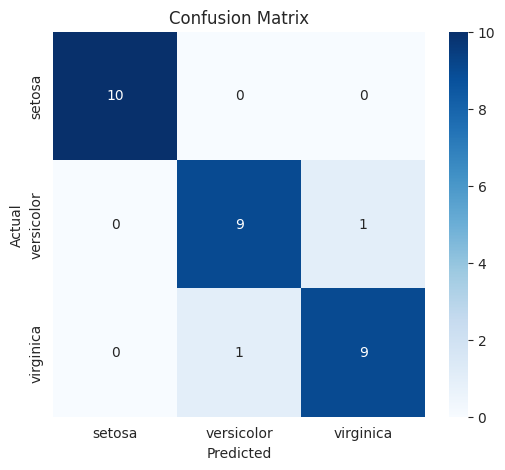

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [16]:
best_model = svm_grid.best_estimator_
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_model.classes_,
            yticklabels=best_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Full report
print(classification_report(y_test, y_pred))

In [17]:
errors = X_test.copy()
errors['actual'] = y_test.values
errors['predicted'] = y_pred
errors = errors[errors['actual'] != errors['predicted']]
print(f"Misclassified: {len(errors)} out of {len(X_test)}")
print(errors)

Misclassified: 2 out of 30
     sepal_length  sepal_width  petal_length  petal_width      actual  \
134           6.1          2.6           5.6          1.4   virginica   
77            6.7          3.0           5.0          1.7  versicolor   

      predicted  
134  versicolor  
77    virginica  


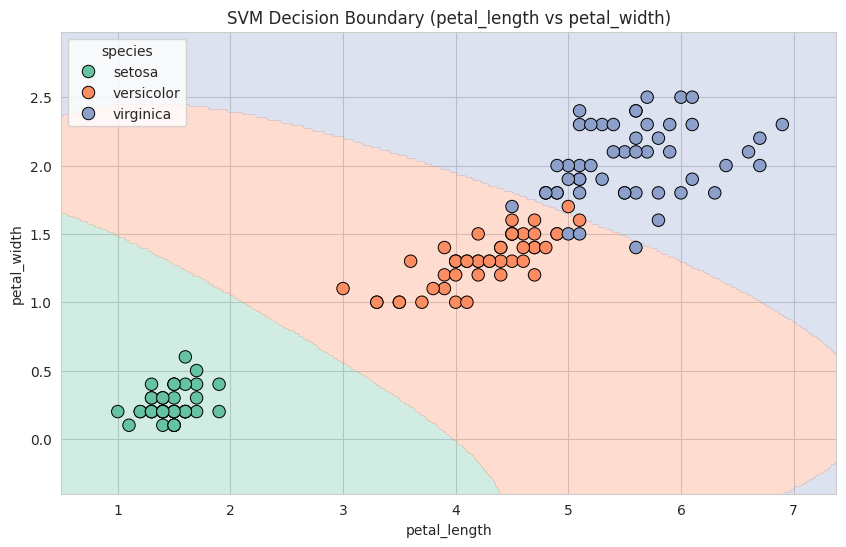

In [19]:
from matplotlib.colors import ListedColormap

# Define your class order and colors
class_order = ['setosa', 'versicolor', 'virginica']
label_to_int = {c: i for i, c in enumerate(class_order)}
cmap = ListedColormap(['#66c2a5', '#fc8d62', '#8da0cb'])  # Set2 colors

# Predict on the grid → 1-D strings
Z = viz_model.predict(pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=['petal_length', 'petal_width']
))

# Map strings → ints, then reshape (vectorized, no LabelEncoder)
Z_int = np.array([label_to_int[label] for label in Z]).reshape(xx.shape)

# Plot
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z_int, alpha=0.3, cmap=cmap, levels=[-0.5, 0.5, 1.5, 2.5])
sns.scatterplot(data=df, x='petal_length', y='petal_width',
                hue='species', palette='Set2',
                edgecolor='k', s=80)
plt.title('SVM Decision Boundary (petal_length vs petal_width)')
plt.show()

        Feature  Importance       Std
3   petal_width    0.242222  0.082072
2  petal_length    0.240000  0.087939
1   sepal_width    0.025556  0.039142
0  sepal_length   -0.001111  0.033866


/tmp/ipykernel_1060/3600533913.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, x='Importance', y='Feature',


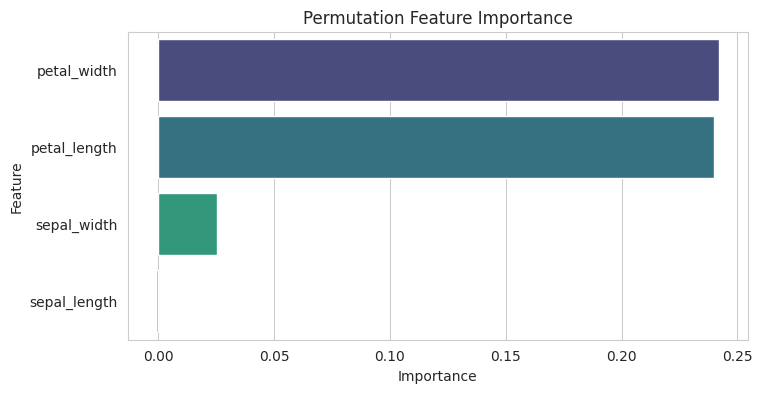

In [20]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=30, random_state=42, n_jobs=-1
)

imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std
}).sort_values('Importance', ascending=False)

print(imp_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=imp_df, x='Importance', y='Feature',
            palette='viridis')
plt.title('Permutation Feature Importance')
plt.show()

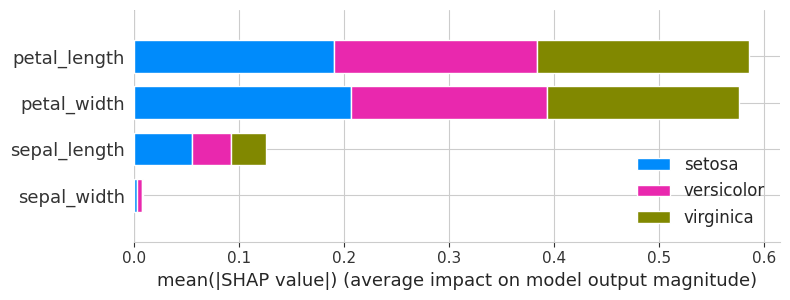

In [21]:
# pip install shap
import shap

# Use a tree model for fast SHAP
tree_model = rf_grid.best_estimator_.named_steps['clf']
tree_model.fit(X_train, y_train)  # refit for SHAP
explainer = shap.TreeExplainer(tree_model)
shap_values = explainer.shap_values(X_test)

# Summary plot (per class)
shap.summary_plot(shap_values, X_test, plot_type="bar",
                  class_names=tree_model.classes_)

In [23]:
import os
import joblib

os.makedirs('models', exist_ok=True)   # ← create folder if missing

joblib.dump(best_model, 'models/iris_model.pkl')
joblib.dump(list(X.columns), 'models/feature_columns.pkl')
print("Saved!")

Saved!


In [24]:
import joblib

joblib.dump(best_model, 'models/iris_model.pkl')
joblib.dump(list(X.columns), 'models/feature_columns.pkl')
print("Saved!")

Saved!


In [25]:
def predict_species(sepal_length, sepal_width, petal_length, petal_width):
    model = joblib.load('models/iris_model.pkl')
    cols = joblib.load('models/feature_columns.pkl')

    X_new = pd.DataFrame([[sepal_length, sepal_width,
                            petal_length, petal_width]], columns=cols)

    pred = model.predict(X_new)[0]
    proba = model.predict_proba(X_new)[0]
    classes = model.classes_

    return pred, dict(zip(classes, proba))

# Test it
pred, proba = predict_species(6.3, 2.9, 5.6, 1.8)
print(f"Predicted: {pred}")
print("Probabilities:", {k: f"{v:.2%}" for k, v in proba.items()})

Predicted: virginica
Probabilities: {'setosa': '1.31%', 'versicolor': '9.57%', 'virginica': '89.12%'}
